# Bayesian Sensitivity Analysis of a Cardiac Cell Model Using a Gaussian Process Emulator: Active Subspaces of the Luo–Rudy 1991 Action Potential

__Eugene T. Y. Chang__, Insigneo Institute for in-silico Medicine, University of Sheffield, and Department of Computer Science, University of Sheffield, Sheffield, United Kingdom

__Mark Strong__, School of Health and Related Research, University of Sheffield, Sheffield, United Kingdom

__Richard H. Clayton__, Insigneo Institute for in-silico Medicine, University of Sheffield, and Department of Computer Science, University of Sheffield, Sheffield, United Kingdom

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

It runs in Python 3 with numpy, scipy and matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later, and takes a few seconds.

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
import convert_data as cd          # names, ranges and the lossless conversion of the PLOS files

SEED = 2015                        # the only seed in this notebook (bootstrap)
t_start = time.perf_counter()
labels = [r'$G_{Na}$', r'$G_{si}$', r'$G_K$', r'$G_{K1}$', r'$G_{Kp}$', r'$G_b$']
qoi_labels = [r'max $dV_m/dt$ (mV/ms)', r'peak $V_m$ (mV)', r'dome $V_m$ (mV)', r'APD$_{90}$ (ms)',
              r'resting $V_m$ (mV)', r'APD$_{50}$ (ms)', 'APDr slope', 'min DI (ms)']

### Summary

Chang, Strong and Clayton [[1]](https://doi.org/10.1371/journal.pone.0130252) ran the Luo–Rudy 1991 (LR1991) ventricular myocyte model [[2]](https://doi.org/10.1161/01.RES.68.6.1501) at 200 Latin hypercube samples of its six maximum ionic conductances, each varied by ±25 % about its published value, recorded eight scalar features of the action potential and its restitution, and published the runs as supporting data. We estimate an active subspace for each feature from these values alone, by the global quadratic estimator (QPHD) with a linear least-squares (OLS) cross-check, and validate one-dimensional surrogates on the paper's 20 separate test runs. The six action-potential features (upstroke velocity, peak, dome and resting potential, APD$_{90}$ and APD$_{50}$) each have a one-dimensional active subspace that predicts the test runs with $R^2 \ge$ 0.990, while the two restitution features have weaker structure.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ normalized inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$ and is nearly constant along $\mathbf W_2^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend, and a surrogate in $\mathbf y$ can replace $f$. Here we have only values of $f$, no gradients, so we estimate $\mathbf C$ from a least-squares quadratic fit and assess it with the bootstrap. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015.

### The model

LR1991 [[2]](https://doi.org/10.1161/01.RES.68.6.1501) describes the membrane potential $V_m$ (mV) of a guinea-pig ventricular myocyte by a current balance with six ionic currents and a stimulus current, all in µA cm$^{-2}$,

$$
C_m\frac{dV_m}{dt} = -\left(I_{Na} + I_{si} + I_K + I_{K1} + I_{Kp} + I_b + I_{stim}\right),
$$

where each ionic current is its maximum conductance $G_x$ (mS cm$^{-2}$) times gating variables and a driving force; the gating variables and the intracellular calcium concentration obey further ODEs (eight state variables in all), given in [[2]](https://doi.org/10.1161/01.RES.68.6.1501). The six inputs are the maximum conductances: fast sodium $G_{Na}$, slow inward (calcium) $G_{si}$, time-dependent potassium $G_K$, time-independent potassium $G_{K1}$, plateau potassium $G_{Kp}$ and background $G_b$ ([[1]](https://doi.org/10.1371/journal.pone.0130252), Table 1, p. 5).

**Simulator** ([[1]](https://doi.org/10.1371/journal.pone.0130252), pp. 4–5). MATLAB code generated from the CellML repository version of LR1991, solved with `ode15s`. Nine S1 stimuli of $-25.5$ µA cm$^{-2}$ for 2 ms at a cycle length of 1000 ms; the outputs come from the ninth action potential. For restitution, the final S1 beat starts a run with an S2 stimulus at progressively shorter cycle lengths until no S2 action potential is elicited; APD$_{90}$ and the diastolic interval (DI) of each S2 beat give the restitution curve, $\mathrm{APD} = a - b\,e^{-\mathrm{DI}/c}$ (Eq. (1), fitted with `fminsearch`), whose maximum slope is $(a/b)\,e^{-\mathrm{DI}_{min}/b}$ (Eq. (2), as printed).

**Quantities of interest** (eight scalars, [[1]](https://doi.org/10.1371/journal.pone.0130252) p. 4 and Table 2): maximum $dV_m/dt$ (mV/ms), peak $V_m$ (mV), dome $V_m$ (mV), APD$_{90}$ (ms), resting $V_m$ (mV), APD$_{50}$ (ms), the maximum slope of the APD restitution curve (APDr slope, dimensionless) and the minimum DI (ms; the shortest DI giving an action potential with APD$_{90} > 100$ ms, p. 17). We analyse all eight and concentrate on APD$_{90}$, the paper's worked example. The six action-potential features are smooth functions of the inputs; the paper itself suspects a discontinuity in minimum DI (p. 17).

**Inputs.** Each conductance is uniform on $G_x \pm G_x/4$, where $G_x$ is the original LR1991 value, sampled by a 200-point Latin hypercube ([[1]](https://doi.org/10.1371/journal.pone.0130252) p. 4). The paper and its data files use normalized inputs $u \in [0, 1]$ with $G_x$ at $u = 0.5$, so the physical value is $G = G_x\,(3/4 + u/2)$; the files here store $G$ in mS cm$^{-2}$ (`convert_data.py`), and the library maps $[G_x - G_x/4,\ G_x + G_x/4]$ to $[-1, 1]$. Table 1 of the paper prints the range ends rounded to four decimals (e.g. 0.0137 for $0.75 \times 0.0183 = 0.013725$); the code uses the exact ends. The paper's sensitivity analysis instead gives each normalized input a normal distribution with mean 0.5 and variance 0.04; we use the uniform design distribution for the active subspace and the normal one only to compare with the paper's indices.

The table is printed from `convert_data.py`.

In [2]:
table1 = {'GNa': '17.250, 28.750', 'Gsi': '0.0675, 0.1125', 'GK': '0.2115, 0.3525',
          'GK1': '0.4535, 0.7559', 'GKp': '0.0137, 0.0229', 'Gb': '0.0294, 0.0490'}
print(f"{'input':6s} {'units':9s} {'G_x (u = 0.5)':>13s} {'lower (u = 0)':>14s} {'upper (u = 1)':>14s}   Table 1 U(.,.)")
for n, g, lo, hi in zip(cd.NAMES, cd.NOMINAL, cd.LOWER, cd.UPPER):
    print(f'{n:6s} {"mS/cm^2":9s} {g:13.5g} {lo:14.8g} {hi:14.8g}   U({table1[n]})')

input  units     G_x (u = 0.5)  lower (u = 0)  upper (u = 1)   Table 1 U(.,.)
GNa    mS/cm^2              23          17.25          28.75   U(17.250, 28.750)
Gsi    mS/cm^2            0.09         0.0675         0.1125   U(0.0675, 0.1125)
GK     mS/cm^2           0.282         0.2115         0.3525   U(0.2115, 0.3525)
GK1    mS/cm^2          0.6047       0.453525       0.755875   U(0.4535, 0.7559)
GKp    mS/cm^2          0.0183       0.013725       0.022875   U(0.0137, 0.0229)
Gb     mS/cm^2         0.03921      0.0294075      0.0490125   U(0.0294, 0.0490)


### Load data

`design.csv` holds the 200 design runs (the paper's S1 Data) and `test.csv` the 20 test runs (S2 Data): six conductances in mS cm$^{-2}$, then the eight outputs. `convert_data.py` wrote them from the unaltered PLOS files in `original/`; the cell confirms that the shipped files are exactly that conversion (see `DATA.md`).

In [3]:
A = np.loadtxt('design.csv', delimiter=',')           # (200, 14): 6 conductances, 8 outputs
At = np.loadtxt('test.csv', delimiter=',')            # (20, 14)
X, F = A[:, :6], A[:, 6:]
Xt, Ft = At[:, :6], At[:, 6:]
same = all(open(name).read() == cd.convert('original/' + src, rows, desc)
           for name, (src, rows, desc) in cd.FILES.items())
print(f'design: X {X.shape}, F {F.shape}; test: X {Xt.shape}, F {Ft.shape}; '
      f'files equal to the conversion of original/: {same}')
print('outputs:', ', '.join(cd.OUTPUTS))

design: X (200, 6), F (200, 8); test: X (20, 6), F (20, 8); files equal to the conversion of original/: True
outputs: dVdt_max, Vm_max, V_dome, APD90, V_rest, APD50, APDr_slope, DI_min


### Estimate the subspace

The paper gives values only, so we cannot use the gradient estimator. With $m = 6$ inputs a full quadratic has $(m+1)(m+2)/2 = 28$ coefficients, and the $M = 200$ design runs are more than the $2 \times 28 = 56$ we ask for, so we use the global quadratic estimator `estimator="qphd"`: it fits $q(\mathbf x) = c + \mathbf g^T\mathbf x + \frac12\mathbf x^T\mathbf H\mathbf x$ by least squares in normalized coordinates and returns $\mathbf C = \mathbf g\mathbf g^T + \mathbf H\boldsymbol\Sigma\mathbf H$ with $\boldsymbol\Sigma = \mathbf I/3$, the covariance of the uniform density on $[-1,1]^6$. The library warns that QPHD's Stein-lemma justification assumes Gaussian inputs; on the uniform design density this $\mathbf C$ is still exactly $\int\nabla q\,\nabla q^T\rho\,d\mathbf x$, the active-subspace matrix of the fitted quadratic, so it is as good as the quadratic fit, whose leave-one-out $R^2$ we print (the warning is silenced below for that reason). As a cross-check we compute the OLS direction (the gradient of the linear least-squares fit) and print $|\mathbf w_{OLS}^T\mathbf w_1|$. The bootstrap (500 replicates, seed `SEED`) resamples the 200 runs and refits the quadratic. Each $\mathbf w_1$ is signed so that the output increases along it (`ac.orient(..., by="covariance")`).

In [4]:
space = ac.Uniform(cd.LOWER, cd.UPPER, names=list(cd.NAMES))
subs, w_ols, loo_quad = [], [], []
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ac.ValidityWarning)   # QPHD/OLS on a uniform space; see text
    for k, q in enumerate(cd.OUTPUTS):
        s = ac.active_subspace(space=space, X=X, f=F[:, k], estimator='qphd', nboot=500, rng=SEED)
        subs.append(ac.orient(s, by='covariance', X=X, f=F[:, k], columns=1))
        w_ols.append(ac.active_subspace(space=space, X=X, f=F[:, k], estimator='ols').W[:, 0])
        loo_quad.append(ac.fit_surrogate(X=X, f=F[:, k], space=space, subspace=None,
                                         kind='poly', degree=2).loo_r_squared)

print(f"{'output':11s} n  {'l1/l2':>7s} {'l2/l3':>6s}  |w_ols.w1|  quad LOO R2   w1 ({', '.join(cd.NAMES)})")
for k, q in enumerate(cd.OUTPUTS):
    lam, w1 = subs[k].eigenvalues, subs[k].W[:, 0]
    print(f'{q:11s} {subs[k].n}  {lam[0] / lam[1]:7.1f} {lam[1] / lam[2]:6.1f}  {abs(w_ols[k] @ w1):10.4f}'
          f'  {loo_quad[k]:11.4f}   {np.array2string(w1, precision=3, suppress_small=True)}')

output      n    l1/l2  l2/l3  |w_ols.w1|  quad LOO R2   w1 (GNa, Gsi, GK, GK1, GKp, Gb)
dVdt_max    1   4688.7   85.8      1.0000       1.0000   [ 0.999 -0.003 -0.     0.021 -0.001 -0.025]
Vm_max      1    236.2   39.5      0.9999       0.9997   [ 0.968  0.012 -0.001 -0.237 -0.026  0.078]
V_dome      1    106.2  136.1      0.9999       0.9996   [ 0.009  0.759 -0.088  0.01  -0.252 -0.594]
APD90       1     89.4   18.5      0.9998       0.9992   [-0.008  0.763 -0.506 -0.146  0.011 -0.375]
V_rest      1    136.5   19.8      0.9995       0.9996   [-0.     0.102  0.004 -0.784 -0.002  0.612]
APD50       1     77.9   39.2      0.9998       0.9994   [-0.008  0.745 -0.532 -0.048  0.043 -0.398]
APDr_slope  1     10.1    9.8      0.9711       0.8937   [-0.147 -0.701  0.524  0.301 -0.019  0.347]
DI_min      1      6.9    2.1      0.9672       0.6076   [-0.255 -0.173  0.694  0.459 -0.193  0.419]


### Results for APD$_{90}$

**Eigenvalues.** The figure shows the six eigenvalues of $\hat{\mathbf C}$ for APD$_{90}$ with 95 % bootstrap intervals.

eigenvalues: [7.8110e+03 8.7375e+01 4.7110e+00 9.3819e-01 6.7160e-01 7.4950e-03]
lambda_1/lambda_2 = 89.4, lambda_2/lambda_3 = 18.5; bootstrap 95% interval of lambda_1 [7699, 7899], of lambda_2 [75.56, 101]; n = 1


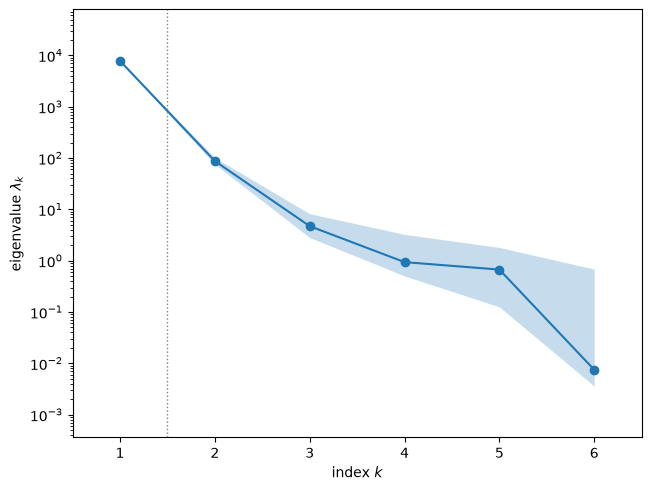

In [5]:
k90 = cd.OUTPUTS.index('APD90')
sub = subs[k90]
lam = sub.eigenvalues
lo, hi = np.percentile(sub.bootstrap_eigenvalues, [2.5, 97.5], axis=0)
print('eigenvalues:', np.array2string(lam, precision=4))
print(f'lambda_1/lambda_2 = {lam[0] / lam[1]:.1f}, lambda_2/lambda_3 = {lam[1] / lam[2]:.1f}; '
      f'bootstrap 95% interval of lambda_1 [{lo[0]:.4g}, {hi[0]:.4g}], of lambda_2 [{lo[1]:.4g}, {hi[1]:.4g}]; '
      f'n = {sub.n}')
fig, ax = ac.plotting.plot_eigenvalues(sub)
plt.close(fig)
fig

The first eigenvalue, $\lambda_1 = 7811$ (ms$^2$ per unit of normalized input squared), is 89.4 times the second ($\lambda_2 = 87.4$), and $\lambda_2/\lambda_3 = 18.5$. The bootstrap intervals are narrow, [7699, 7899] for $\lambda_1$ and [75.6, 101] for $\lambda_2$, so the gap is not an artifact of the 200 samples, and the eigenvalue-gap rule picks $n = 1$. The eigenvalues come from the fitted quadratic, so they measure the quadratic's gradients; its leave-one-out $R^2$ is 0.9992.

bootstrap mean subspace distance, k = 1..5: [0.005 0.054 0.22  0.612 0.422]


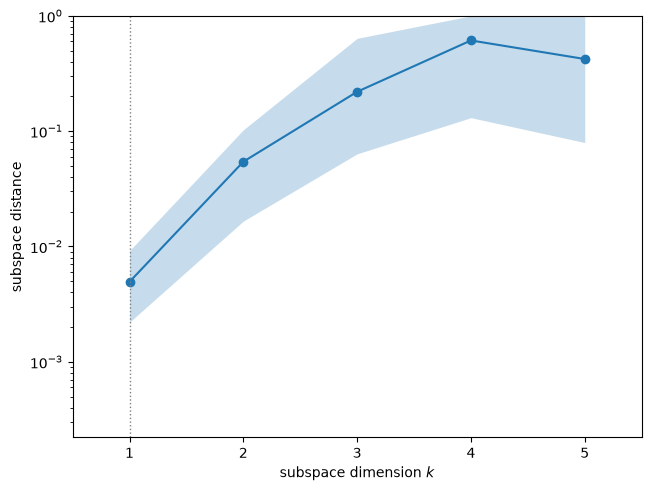

In [6]:
fig, ax = ac.plotting.plot_subspace_errors(sub)
plt.close(fig)
print('bootstrap mean subspace distance, k = 1..5:',
      np.array2string(sub.bootstrap_distances.mean(axis=0), precision=3))
fig

The bootstrap mean distance between the estimated and resampled subspaces is 0.005 for $k = 1$, 0.054 for $k = 2$ and 0.22 for $k = 3$: the one-dimensional subspace is very stable under resampling of the design, and the two-dimensional one is also well determined.

w1: GNa -0.008, Gsi +0.763, GK -0.506, GK1 -0.146, GKp +0.011, Gb -0.375
w2: GNa +0.007, Gsi +0.552, GK +0.828, GK1 +0.094, GKp -0.012, Gb -0.032


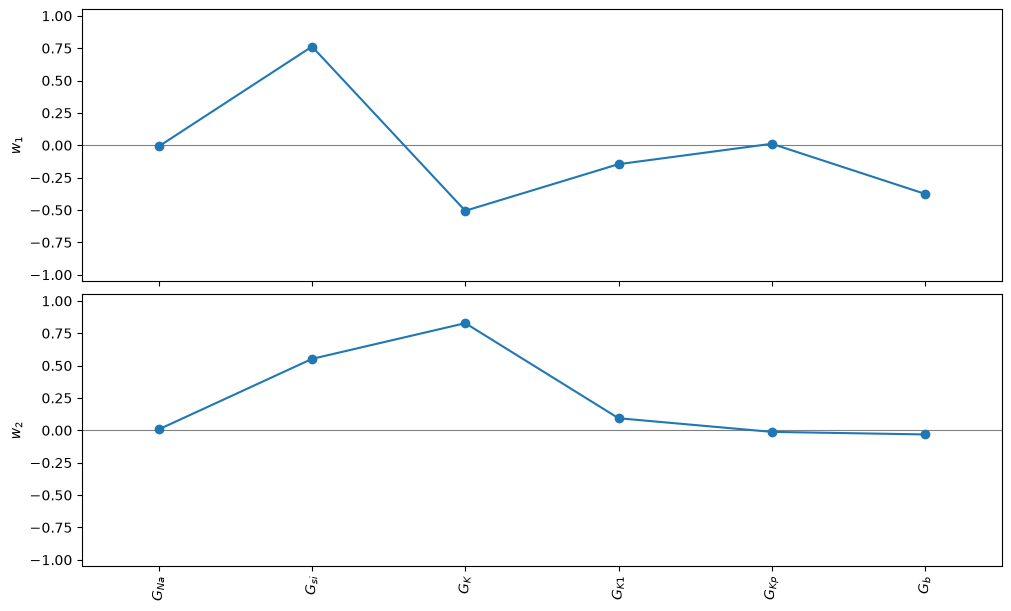

In [7]:
fig, axes = ac.plotting.plot_eigenvectors(sub, indices=[0, 1], labels=labels, figsize=(10, 6))
plt.close(fig)
w1 = sub.W[:, 0]
print('w1:', ', '.join(f'{n} {w:+.3f}' for n, w in zip(cd.NAMES, w1)))
print('w2:', ', '.join(f'{n} {w:+.3f}' for n, w in zip(cd.NAMES, sub.W[:, 1])))
fig

The first eigenvector is dominated by $G_{si}$ (+0.763), $G_K$ (−0.506) and $G_b$ (−0.375), with a smaller $G_{K1}$ weight (−0.146); $G_{Na}$ (−0.008) and $G_{Kp}$ (+0.011) hardly matter. APD$_{90}$ grows with the inward calcium current and shrinks with the outward potassium and background currents, as the paper describes for its mean effects (p. 10, Fig. 5). The second eigenvector is mostly $G_K$ (+0.828) and $G_{si}$ (+0.552).

active variable y = w1^T x: design range [-1.45, 1.30]; corr(y, APD90) = 0.9916


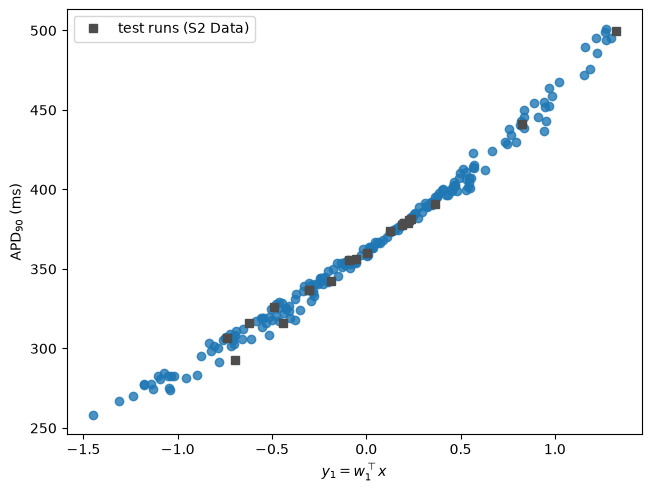

In [8]:
fig, ax = ac.plotting.plot_sufficient_summary(sub, X=X, f=F[:, k90], dims=1, qoi_label=qoi_labels[k90])
ax.plot(space.to_normalized(Xt) @ w1, Ft[:, k90], 's', color='0.3', ms=6, label='test runs (S2 Data)')
ax.legend()
plt.close(fig)
y = space.to_normalized(X) @ w1
print(f'active variable y = w1^T x: design range [{y.min():.2f}, {y.max():.2f}]; '
      f'corr(y, APD90) = {np.corrcoef(y, F[:, k90])[0, 1]:.4f}')
fig

APD$_{90}$ follows a single smooth, slightly convex trend in $y = \mathbf w_1^T\mathbf x$ (design range $[-1.45, 1.30]$), with correlation 0.9916 between $y$ and APD$_{90}$; the 20 test runs (gray squares), which were not used to find $\mathbf w_1$, fall on the same trend.

### All eight outputs

Sufficient summary plots on the first active variable of each output, design runs in color and test runs in gray.

|w1(APD50) . w1(APD90)| = 0.9939; corr(APDr_slope, Gsi) = -0.55


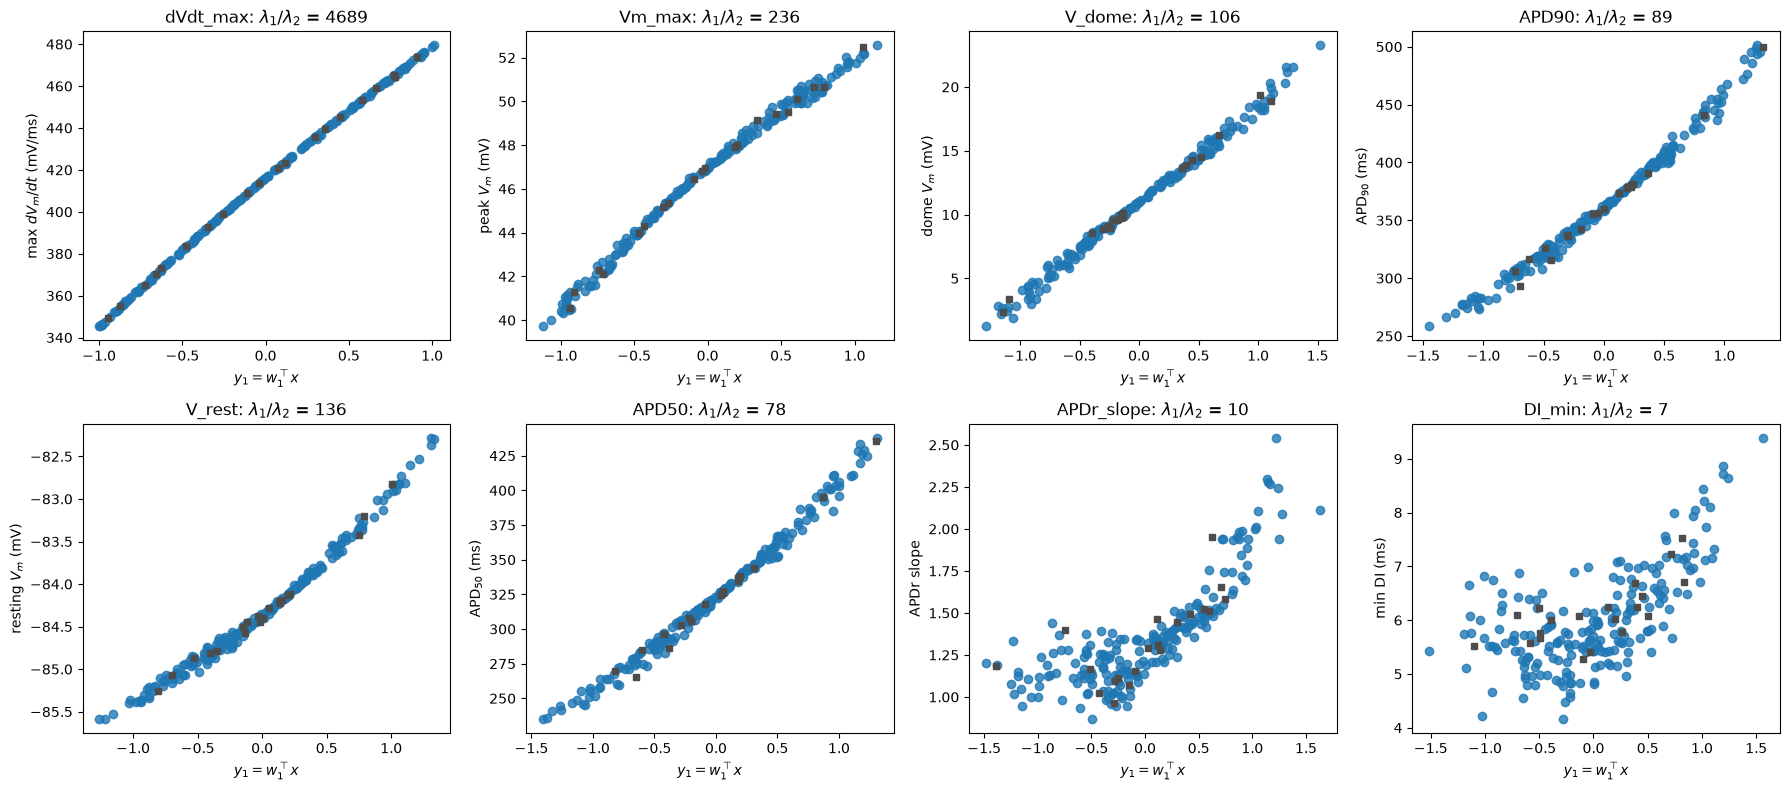

In [9]:
Xn, Xtn = space.to_normalized(X), space.to_normalized(Xt)
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for k, ax in enumerate(axes.flat):
    ac.plotting.plot_sufficient_summary(subs[k], X=X, f=F[:, k], dims=1, qoi_label=qoi_labels[k], ax=ax)
    ax.plot(Xtn @ subs[k].W[:, 0], Ft[:, k], 's', color='0.3', ms=5)
    ax.set_title(f'{cd.OUTPUTS[k]}: ' + r'$\lambda_1/\lambda_2$' + f' = {subs[k].eigenvalues[0] / subs[k].eigenvalues[1]:.0f}')
fig.tight_layout()
k50 = cd.OUTPUTS.index('APD50')
print(f'|w1(APD50) . w1(APD90)| = {abs(subs[k50].W[:, 0] @ subs[k90].W[:, 0]):.4f}; '
      f'corr(APDr_slope, Gsi) = {np.corrcoef(X[:, 1], F[:, 6])[0, 1]:+.2f}')
plt.close(fig)
fig

The eigenvalue-gap rule picks $n = 1$ for all eight outputs (table above). For the six action-potential features the gaps are large: $\lambda_1/\lambda_2 = 4689$ for max $dV_m/dt$, 236 for peak $V_m$, 106 for dome $V_m$, 89.4 for APD$_{90}$, 136 for resting $V_m$ and 77.9 for APD$_{50}$, and the OLS direction agrees with the QPHD $\mathbf w_1$ to $|\mathbf w_{OLS}^T\mathbf w_1| \ge 0.9995$. Max $dV_m/dt$ is essentially a function of $G_{Na}$ alone ($w_{1,Na} = 0.999$), and peak $V_m$ nearly so ($G_{Na}$ 0.968, $G_{K1}$ −0.237). Dome $V_m$ combines $G_{si}$ (+0.759), $G_b$ (−0.594) and $G_{Kp}$ (−0.252); resting $V_m$ is set by $G_{K1}$ (−0.784) and $G_b$ (+0.612); and APD$_{50}$ has nearly the direction of APD$_{90}$ ($|\mathbf w_1^{50}\cdot\mathbf w_1^{90}| = 0.9939$). The two restitution outputs are different: $\lambda_1/\lambda_2$ is only 10.1 for the APDr slope and 6.9 for the minimum DI, their summary plots scatter widely, and even the full quadratic fits them poorly (leave-one-out $R^2$ 0.894 and 0.608), so the quadratic-based $\mathbf C$ is unreliable for them. The paper notes a possible discontinuity in the minimum DI (p. 17), and the summary plot shows no clean trend.

### Surrogates on the first active variable, validated on the test runs

For each output we fit a quadratic in $y = \mathbf w_1^T\mathbf x$ to the 200 design runs, report its leave-one-out $R^2$, and predict the 20 test runs, which played no part in estimating $\mathbf w_1$ or the surrogate. For comparison, the last column is the test $R^2$ of the full quadratic in all six inputs (28 coefficients), on which QPHD is built.

output      LOO R2 (1-D) test R2 (1-D)  test RMSE  test R2 (full quad)
dVdt_max          0.9999        0.9999     0.3707               1.0000
Vm_max            0.9963        0.9964     0.2013               0.9999
V_dome            0.9930        0.9948      0.306               0.9995
APD90             0.9935        0.9920      4.134               0.9989
V_rest            0.9954        0.9929    0.04892               0.9993
APD50             0.9929        0.9903      3.793               0.9995
APDr_slope        0.8263        0.7122     0.1299               0.7938
DI_min            0.6065        0.4918     0.4047               0.6213


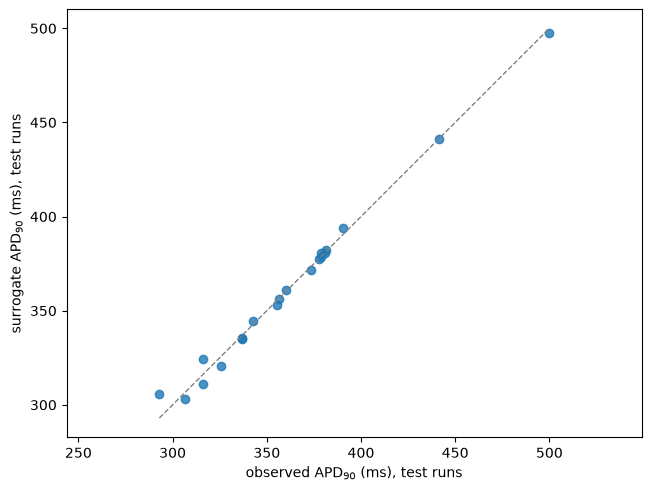

In [10]:
def r2(pred, obs):
    return 1 - np.sum((pred - obs)**2) / np.sum((obs - obs.mean())**2)

surs, r2_test, r2_quad = [], [], []
for k in range(8):
    sur = ac.fit_surrogate(X=X, f=F[:, k], subspace=ac.with_dimension(subs[k], 1), kind='poly', degree=2)
    quad = ac.fit_surrogate(X=X, f=F[:, k], space=space, subspace=None, kind='poly', degree=2)
    surs.append(sur)
    r2_test.append(r2(ac.predict(sur, Xt), Ft[:, k]))
    r2_quad.append(r2(ac.predict(quad, Xt), Ft[:, k]))
print(f"{'output':11s} {'LOO R2 (1-D)':>12s} {'test R2 (1-D)':>13s} {'test RMSE':>10s} {'test R2 (full quad)':>20s}")
for k, q in enumerate(cd.OUTPUTS):
    rmse = np.sqrt(np.mean((ac.predict(surs[k], Xt) - Ft[:, k])**2))
    print(f'{q:11s} {surs[k].loo_r_squared:12.4f} {r2_test[k]:13.4f} {rmse:10.4g} {r2_quad[k]:20.4f}')
fig, ax = ac.plotting.plot_surrogate_fit(surs[k90], X=Xt, f=Ft[:, k90], qoi_label=qoi_labels[k90] + ', test runs')
plt.close(fig)
fig

For the six action-potential features a quadratic in one active variable predicts the 20 test runs with $R^2$ between 0.9903 (APD$_{50}$) and 0.9999 (max $dV_m/dt$); for APD$_{90}$ the test RMSE is 4.13 ms on a range of about 240 ms (test $R^2$ = 0.9920, leave-one-out $R^2$ = 0.9935). The full six-input quadratic does somewhat better ($R^2 \ge 0.9989$ on the test runs), so the remaining directions carry a small part of the variation. For the restitution outputs both surrogates are poor: test $R^2$ 0.71 (APDr slope) and 0.49 (minimum DI) in one variable, 0.79 and 0.62 with the full quadratic.

### Comparison with the paper

The paper reports Gaussian-process emulator summaries (Table 2) and main-effect (first-order Sobol) indices (Fig. 8) under its sensitivity-analysis distribution, independent normals with mean 0.5 and variance 0.04 in normalized units $u$. It does not compute an active subspace. To compare like with like we compute the same quantities from the full least-squares quadratic (the one QPHD uses), fitted in $z = u - 0.5$: for $q(\mathbf z) = c + \sum_j b_j z_j + \sum_j a_{jj} z_j^2 + \sum_{j<k} a_{jk} z_j z_k$ with $z_j \sim N(0, s^2)$, $s^2 = 0.04$, the mean is $c + s^2\sum_j a_{jj}$, the main-effect variance of input $j$ is $V_j = b_j^2 s^2 + 2a_{jj}^2 s^4$, and the total variance is $\sum_j V_j + s^4\sum_{j<k}a_{jk}^2$. The paper's values are copied from Table 2 and from the numbers printed in Fig. 8 (p. 15).

In [11]:
iu = np.triu_indices(6, 1)
Z = (X - cd.LOWER) / (cd.UPPER - cd.LOWER) - 0.5            # z = u - 0.5
B = np.hstack([np.ones((len(Z), 1)), Z, Z**2, Z[:, iu[0]] * Z[:, iu[1]]])
s2 = 0.04
fig8 = {'dVdt_max': [1.00, 0.00, 0.00, 0.00, 0.00, 0.00], 'Vm_max': [0.93, 0.00, 0.00, 0.06, 0.00, 0.01],
        'V_dome': [0.02, 0.55, 0.01, 0.02, 0.04, 0.33], 'APD90': [0.00, 0.58, 0.24, 0.02, 0.00, 0.14],
        'V_rest': [0.00, 0.01, 0.00, 0.59, 0.00, 0.39], 'APD50': [0.01, 0.55, 0.26, 0.01, 0.01, 0.15],
        'APDr_slope': [0.00, 0.47, 0.24, 0.07, 0.00, 0.07], 'DI_min': [0.02, 0.01, 0.16, 0.02, 0.01, 0.05]}
table2 = {'dVdt_max': (414.68, 415.55, 6.42), 'Vm_max': (46.67, 46.83, 4.92), 'V_dome': (10.98, 11.00, 26.87),
          'APD90': (365.37, 363.02, 9.48), 'V_rest': (-84.29, -84.33, 0.58), 'APD50': (325.77, 324.66, 9.20),
          'APDr_slope': (2.02, 2.11, 22.80), 'DI_min': (10.02, 6.01, 13.27)}   # design mean, E*[E f], CoV %
S_quad = {}
print(f"{'output':11s} {'design mean':>17s} {'E[f], normal':>17s} {'CoV %':>13s}   main-effect indices "
      f"({', '.join(cd.NAMES)}), sum: paper (Fig. 8) / quadratic")
for k, q in enumerate(cd.OUTPUTS):
    c = np.linalg.lstsq(B, F[:, k], rcond=None)[0]
    b, a, x = c[1:7], c[7:13], c[13:]
    Vj = b**2 * s2 + 2 * a**2 * s2**2
    V = Vj.sum() + np.sum(x**2) * s2**2
    mean = c[0] + s2 * a.sum()
    S_quad[q] = Vj / V
    p = table2[q]
    print(f'{q:11s} {p[0]:8.2f}/{F[:, k].mean():8.2f} {p[1]:8.2f}/{mean:8.2f} {p[2]:6.2f}/{100 * np.sqrt(V) / abs(mean):6.2f}   '
          f'{" ".join(f"{v:.2f}" for v in fig8[q])} ({sum(fig8[q]):.2f}) / '
          f'{" ".join(f"{v:.2f}" for v in S_quad[q])} ({S_quad[q].sum():.2f})')
dev6 = max(np.max(np.abs(np.array(fig8[q]) - S_quad[q])) for q in cd.OUTPUTS[:6])
print(f'largest |paper - quadratic| index difference over the six action-potential outputs: {dev6:.2f}')
print(f'APD90: w1^2 = {np.array2string(subs[k90].W[:, 0]**2, precision=2)}; '
      f'paper text p. 10: indices sum to 98.4%, here {100 * S_quad["APD90"].sum():.1f}%')

output            design mean      E[f], normal         CoV %   main-effect indices (GNa, Gsi, GK, GK1, GKp, Gb), sum: paper (Fig. 8) / quadratic
dVdt_max      414.68/  414.68   415.55/  415.55   6.42/  6.42   1.00 0.00 0.00 0.00 0.00 0.00 (1.00) / 1.00 0.00 0.00 0.00 0.00 0.00 (1.00)
Vm_max         46.67/   46.67    46.83/   46.84   4.92/  4.91   0.93 0.00 0.00 0.06 0.00 0.01 (1.00) / 0.93 0.00 0.00 0.06 0.00 0.01 (1.00)
V_dome         10.98/   10.98    11.00/   11.02  26.87/ 27.23   0.02 0.55 0.01 0.02 0.04 0.33 (0.97) / 0.00 0.57 0.01 0.00 0.06 0.35 (1.00)
APD90         365.37/  365.37   363.02/  362.86   9.48/  9.66   0.00 0.58 0.24 0.02 0.00 0.14 (0.98) / 0.00 0.59 0.25 0.02 0.00 0.14 (0.99)
V_rest        -84.29/  -84.29   -84.33/  -84.34   0.58/  0.58   0.00 0.01 0.00 0.59 0.00 0.39 (0.99) / 0.00 0.01 0.00 0.60 0.00 0.39 (1.00)
APD50         325.77/  325.78   324.66/  324.61   9.20/  9.30   0.01 0.55 0.26 0.01 0.01 0.15 (0.99) / 0.00 0.56 0.28 0.00 0.00 0.16 (0.99)
APDr_slope    

For the six action-potential features the shipped data reproduce the paper's numbers: the design means equal Table 2 (column 2) to 0.01, the means and coefficients of variation under the normal inputs are within 0.4 of the GP emulator's values (e.g. APD$_{90}$: 362.86 ms against 363.02, CoV 9.66 % against 9.48 %; the largest difference is the CoV of dome $V_m$, 27.23 % against 26.87 %), and the quadratic's main-effect indices differ from Fig. 8 by at most 0.02. For APD$_{90}$ the squared components of $\mathbf w_1$ (0.58 for $G_{si}$, 0.26 for $G_K$, 0.14 for $G_b$, 0.02 for $G_{K1}$) are close to the paper's main-effect indices (0.58, 0.24, 0.14, 0.02), as expected for a nearly additive, nearly linear output; the sum of the indices is 99.4 % here against 98.4 % in the paper (p. 10).

The two restitution columns do not match the paper's summaries: their design means are 1.36 and 6.00 ms, against 2.02 and 10.02 ms in Table 2, and their main-effect indices differ from Fig. 8 (for the minimum DI they sum to 0.78, against the paper's 0.26). The values in the files do match the ranges plotted in the paper's Fig. 2 (APDr slope about 0.9–2.5, minimum DI about 4–9.4 ms). The paper's text also says that increasing $G_{si}$ increases the APDr slope (p. 13, Fig. 7(f)), while in these data the slope falls with $G_{si}$ (correlation −0.55, also visible in Fig. 2). We cannot tell from the paper which is right, so the restitution outputs are reported here but not interpreted; see `DATA.md`.

| Quantity | Paper value | Notebook value |
|---|---|---|
| Design mean of APD$_{90}$ (ms) | 365.37 (Table 2) | 365.37 |
| $E[\mathrm{APD}_{90}]$ under $N(0.5, 0.04)$ inputs (ms) | 363.02 (GP emulator, Table 2) | 362.86 (quadratic) |
| CoV of APD$_{90}$ under $N(0.5, 0.04)$ | 9.48 % (Table 2) | 9.66 % |
| APD$_{90}$ main effects $G_{si}$, $G_K$, $G_b$, $G_{K1}$ | 0.58, 0.24, 0.14, 0.02 (Fig. 8) | 0.59, 0.25, 0.14, 0.02 (quadratic); $w_1^2$: 0.58, 0.26, 0.14, 0.02 |
| Sum of APD$_{90}$ main effects | 98.4 % (p. 10) | 99.4 % |
| Largest main-effect difference, six action-potential outputs | — | 0.02 |
| Resting $V_m$ main effects $G_{K1}$, $G_b$ | 0.59, 0.39 (Fig. 8) | 0.60, 0.39 |
| Design mean of APDr slope / minimum DI (ms) | 2.02 / 10.02 (Table 2) | 1.36 / 6.00 |
| Sum of main effects, APDr slope / minimum DI | 0.85 / 0.26 (pp. 13, 15, 17) | 0.89 / 0.78 |
| Active subspace | not reported | $n = 1$ for every output; APD$_{90}$: $\lambda_1/\lambda_2 = 89.4$ |
| Test-set check | Mahalanobis distance 28.22 for APD$_{90}$ (p. 9) | test $R^2$ = 0.9920 (1-D quadratic) |

### References

[1] E. T. Y. Chang, M. Strong, and R. H. Clayton. [Bayesian sensitivity analysis of a cardiac cell model using a Gaussian process emulator](https://doi.org/10.1371/journal.pone.0130252). *PLoS ONE*, 10(6):e0130252, 2015. Supporting information S1 Data and S2 Data (CC BY 4.0).

[2] C. H. Luo and Y. Rudy. [A model of the ventricular cardiac action potential. Depolarization, repolarization, and their interaction](https://doi.org/10.1161/01.RES.68.6.1501). *Circulation Research*, 68(6):1501–1526, 1991.

[3] P. G. Constantine. [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860). SIAM, 2015.

[R1]: https://doi.org/10.1371/journal.pone.0130252
[R2]: https://doi.org/10.1161/01.RES.68.6.1501

### Acknowledgments

From [[1]][R1]: "This work was supported by the UK Engineering and Physical Sciences Research Council (www.epsrc.ac.uk) grant number EP/K037145/1. Mark Strong is funded by a post-doctoral fellowship grant from the National Institute for Health Research http://www.nihr.ac.uk (Post-Doctoral Fellowship, PDF-2012-05-258)." The design and test data were produced on the iceberg compute resource at the University of Sheffield.

In [12]:
print(f'Total run time: {time.perf_counter() - t_start:.1f} s')

Total run time: 7.9 s
